Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [l2_effectiveness]


Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 1 seconds.


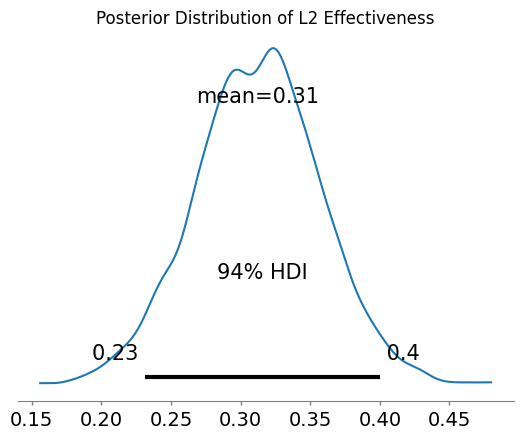

Optimal L2 norm according to posterior: 0.31240769280961106


In [3]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Initialize a deque to store data for the last E iterations
E = 5  # Size of the rolling window
l2_norms_history = deque(maxlen=E)
performance_history = deque(maxlen=E)

# Simulate data entry (for demonstration purposes)
# In practice, fill these with actual L2 norms and performance metrics
for _ in range(E):
    l2_norms_history.append(np.random.uniform(0.1, 2.0))
    performance_history.append(np.random.uniform(0.2, 0.8))  # Lower is better

# Bayesian model using last E iterations
with pm.Model() as model:
    # Prior for L2 norm effectiveness (assumed normally distributed)
    l2_effectiveness = pm.Normal('l2_effectiveness', mu=1.0, sigma=1.0)
    
    # Likelihood function: Gaussian likelihood
    observed_performance = pm.Normal('observed_performance', mu=l2_effectiveness, sigma=0.1, 
                                     observed=list(performance_history))
    
    # Sample from the posterior
    trace = pm.sample(1000, tune=500)  # return_inferencedata=True by default


# Plot the results
pm.plot_posterior(trace, var_names=['l2_effectiveness'])
plt.title('Posterior Distribution of L2 Effectiveness')
plt.show()

# Determine the optimal L2 norm according to the posterior
l2_samples = trace.posterior["l2_effectiveness"].values
optimal_l2 = np.mean(l2_samples)
print(f"Optimal L2 norm according to posterior: {optimal_l2}")

# Example: Update the deque with new data for the next iteration
# This simulates the process over multiple iterations
new_l2_norm = np.random.uniform(0.1, 2.0)
new_performance = np.random.uniform(0.2, 0.8)

l2_norms_history.append(new_l2_norm)
performance_history.append(new_performance)
